# Lab - Análisis Exploratorio Univariado: Amazon UK Product Insights

## Objetivo de negocio.

El objetivo de este análisis es explorar los productos publicados en Amazon UK para entender la distribución de categorías, precios y valoraciones de clientes.

Este análisis puede ayudar a una empresa a tomar mejores decisiones sobre:

- posicionamiento de productos,
- estrategia de precios,
- gestión de catálogo,
- priorización de inventario,
- análisis de percepción del cliente.

In [ ]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:

# Carga de Dataset
import pandas as pd

df = pd.read_csv("/Users/gabrielbohorquez/Desktop/Ironhack/Semana_5/Dia_1_11_Mayo/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")
print(df.shape)

(2443651, 9)


In [ ]:
# Revisar información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isbestseller       bool   
 7   boughtinlastmonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [ ]:
# Ver nombre de columnas
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isbestseller',
       'boughtinlastmonth', 'category'],
      dtype='object')

In [ ]:
# Limpiar nombres de columnas
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isbestseller',
       'boughtinlastmonth', 'category'],
      dtype='object')

In [ ]:
df.head()

,uid,asin,title,stars,reviews,price,isbestseller,boughtinlastmonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:
# Revisar valores nulos
df.isna().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isbestseller         0
boughtinlastmonth    0
category             0
dtype: int64

## Parte 1: Análisis de categorías de producto

### Pregunta de negocio

¿Cuáles son las categorías de productos más populares en Amazon UK y cómo se comparan según la frecuencia de publicaciones?

En esta sección analizaremos cuántos productos aparecen en cada categoría para identificar cuáles tienen mayor presencia dentro del marketplace.

In [ ]:
# Definir columna de categoría
category_col = "category"

df[category_col].head()

0    Hi-Fi Speakers
1    Hi-Fi Speakers
2    Hi-Fi Speakers
3    Hi-Fi Speakers
4    Hi-Fi Speakers
Name: category, dtype: object

In [ ]:
# Crear tabla de frecuencia
category_frequency = df["category"].value_counts()
print(category_frequency)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [ ]:
category_frequency = df["category"].value_counts()
print(category_frequency)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [ ]:
# 5 categorías más listadas
top_5_categories = category_frequency.head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

### Interpretación

La tabla de frecuencias muestra cuántos productos hay publicados en cada categoría.

Las 5 categorías con más productos representan las áreas con mayor presencia dentro del catálogo de Amazon UK.

Desde una perspectiva de negocio, estas categorías pueden indicar:

- mayor demanda potencial,
- mayor competencia entre vendedores,
- mayor saturación del mercado,
- mayor necesidad de diferenciación en precio, marca o valoraciones.

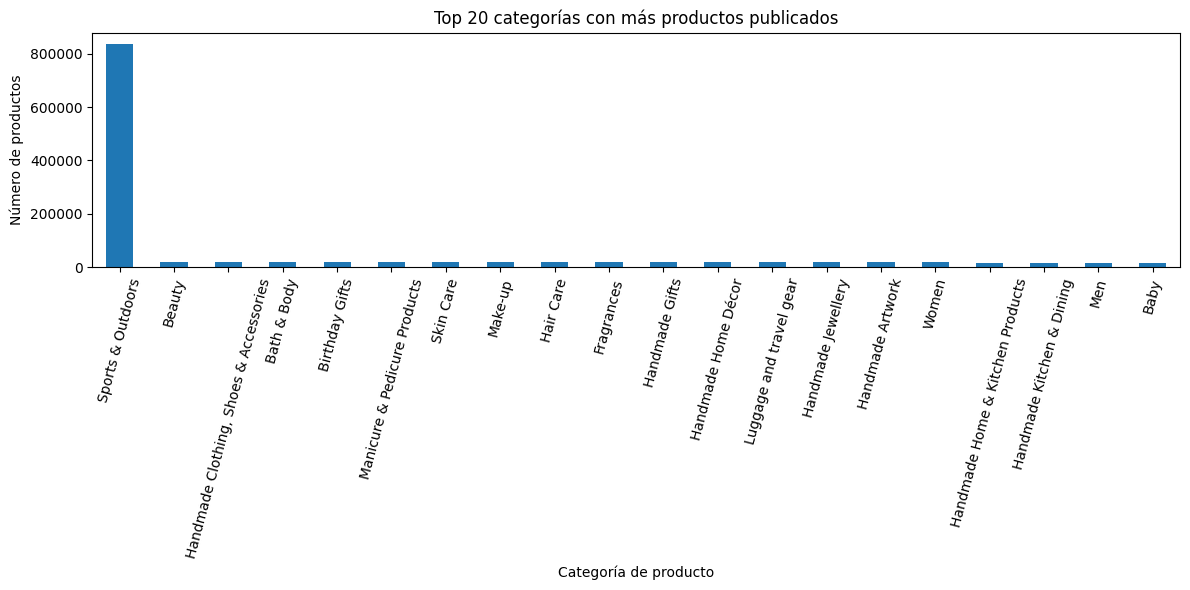

In [ ]:
# Gráfico de barras con top 20 categorías
top_20_categories = category_frequency.head(20)

plt.figure(figsize=(12, 6))
top_20_categories.plot(kind="bar")
plt.title("Top 20 categorías con más productos publicados")
plt.xlabel("Categoría de producto")
plt.ylabel("Número de productos")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

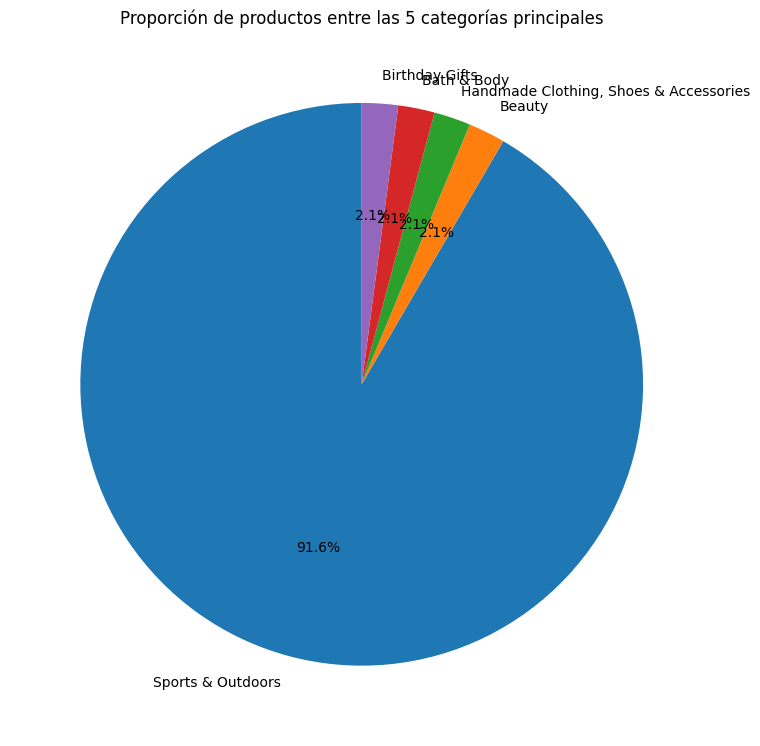

In [ ]:
# Gráfico circular con top 5 categorías
plt.figure(figsize=(8, 8))
top_5_categories.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Proporción de productos entre las 5 categorías principales")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Conclusión de negocio - Categorías

El análisis de categorías permite identificar qué tipos de productos tienen mayor presencia en Amazon UK.

Si una categoría domina claramente el gráfico, esto puede indicar que esa categoría está muy desarrollada dentro del marketplace. Sin embargo, una mayor cantidad de productos también puede significar mayor competencia.

Para una empresa, esta información es útil porque permite detectar:

- categorías saturadas,
- categorías con alta actividad comercial,
- posibles oportunidades de diferenciación,
- áreas donde puede ser necesario competir con precio, marca, calidad o valoraciones.

## Parte 2: Análisis de precios de productos

### Pregunta de negocio

¿Cómo están distribuidos los precios de los productos en Amazon UK?

En esta sección analizaremos el comportamiento de los precios para entender el precio típico, la dispersión y la posible existencia de productos extremadamente caros.

In [ ]:
# Definir columna de precio
price_col = "price"

df[price_col].head()

0    21.99
1    23.99
2    21.99
3    31.99
4    17.99
Name: price, dtype: float64

In [ ]:
# Limpiar y convertir precio a número (quitar símbolos y convertirlo a número)
df[price_col] = (
    df[price_col]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.replace(",", "", regex=False)
)

df[price_col] = pd.to_numeric(df[price_col], errors="coerce")

df[price_col].head()


0    21.99
1    23.99
2    21.99
3    31.99
4    17.99
Name: price, dtype: float64

In [ ]:
# revisar valores nulos en precio
df[price_col].isna().sum()

np.int64(0)

In [ ]:
# crear variable con precios válidos
price_data = df[price_col].dropna()

price_data.describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

## Medidas de centralidad del precio

In [ ]:
price_mean = price_data.mean()
price_median = price_data.median()
price_mode = price_data.mode()[0]

print(f"Precio medio: {price_mean:.2f}")
print(f"Precio mediano: {price_median:.2f}")
print(f"Precio más frecuente: {price_mode:.2f}")

Precio medio: 89.24
Precio mediano: 19.09
Precio más frecuente: 9.99


### Interpretación - Medidas de centralidad del precio

La media indica el precio promedio de los productos.

La mediana indica el precio central, es decir, el valor que divide los productos en dos mitades.

La moda indica el precio que más se repite.

Si la media es mucho mayor que la mediana, esto puede indicar que existen productos muy caros que empujan el promedio hacia arriba.

En ese caso, la mediana suele representar mejor el precio típico de los productos.

## Medidas de dispersión del precio

In [ ]:
price_variance = price_data.var()
price_std = price_data.std()
price_range = price_data.max() - price_data.min()
price_iqr = price_data.quantile(0.75) - price_data.quantile(0.25)

print(f"Varianza: {price_variance:.2f}")
print(f"Desviación estándar: {price_std:.2f}")
print(f"Rango: {price_range:.2f}")
print(f"Rango intercuartílico IQR: {price_iqr:.2f}")

Varianza: 119445.49
Desviación estándar: 345.61
Rango: 100000.00
Rango intercuartílico IQR: 36.00


### Interpretación - Dispersión del precio

La varianza y la desviación estándar muestran cuánto varían los precios respecto al promedio.

El rango muestra la diferencia entre el producto más barato y el más caro.

El IQR muestra la dispersión del 50% central de los productos, por lo que es más resistente a valores extremos.

Si el rango o la desviación estándar son muy altos, puede significar que hay productos con precios extremadamente altos en comparación con la mayoría.

## Visualización de precios

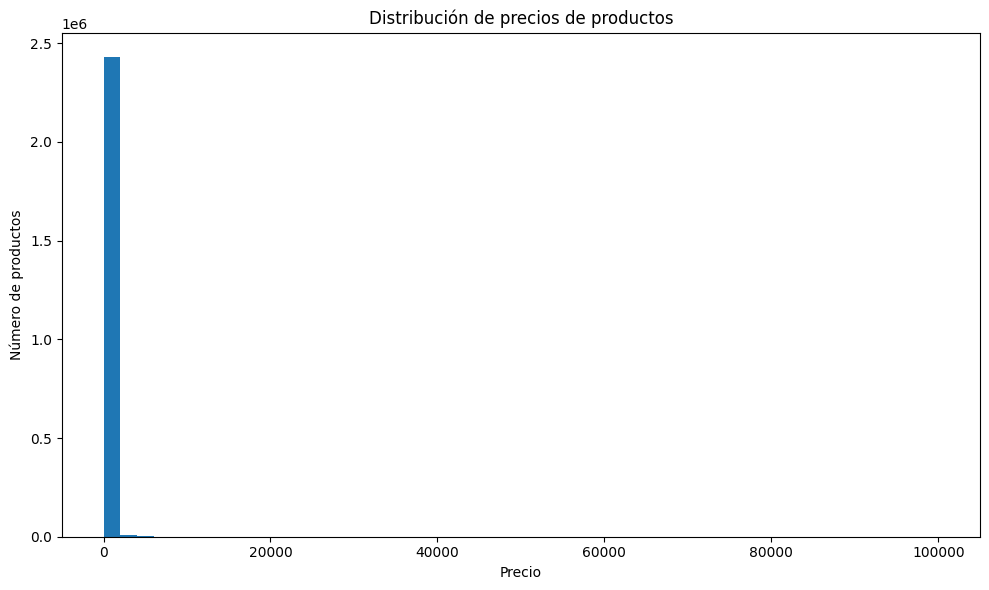

In [ ]:
# histograma de precios
plt.figure(figsize=(10, 6))
plt.hist(price_data, bins=50)
plt.title("Distribución de precios de productos")
plt.xlabel("Precio")
plt.ylabel("Número de productos")
plt.tight_layout()
plt.show()

### Interpretación del histograma de precios

El histograma permite ver en qué rangos de precio se concentra la mayoría de productos.

Si el gráfico es difícil de leer, probablemente se debe a la existencia de productos extremadamente caros.

Estos valores extremos estiran el eje horizontal y hacen que la mayoría de productos aparezcan comprimidos en la parte izquierda del gráfico.

Una forma de solucionarlo es crear una visualización filtrando los precios hasta el percentil 95. Esto no elimina los datos originales, solo mejora la lectura visual.

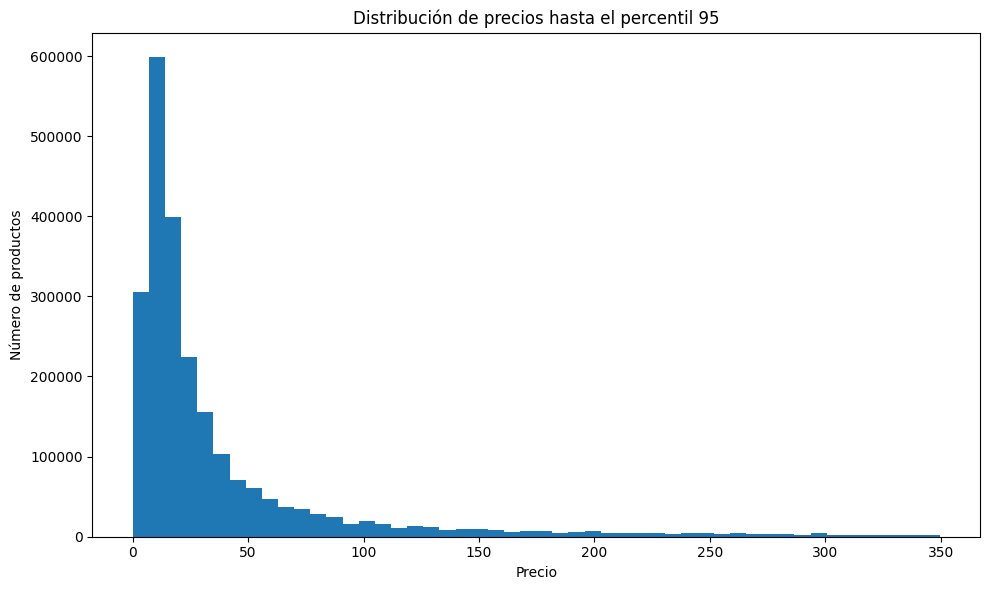

In [ ]:
# histograma filtrado hasta percentil 95
price_95 = price_data.quantile(0.95)

filtered_price_data = price_data[price_data <= price_95]

plt.figure(figsize=(10, 6))
plt.hist(filtered_price_data, bins=50)
plt.title("Distribución de precios hasta el percentil 95")
plt.xlabel("Precio")
plt.ylabel("Número de productos")
plt.tight_layout()
plt.show()

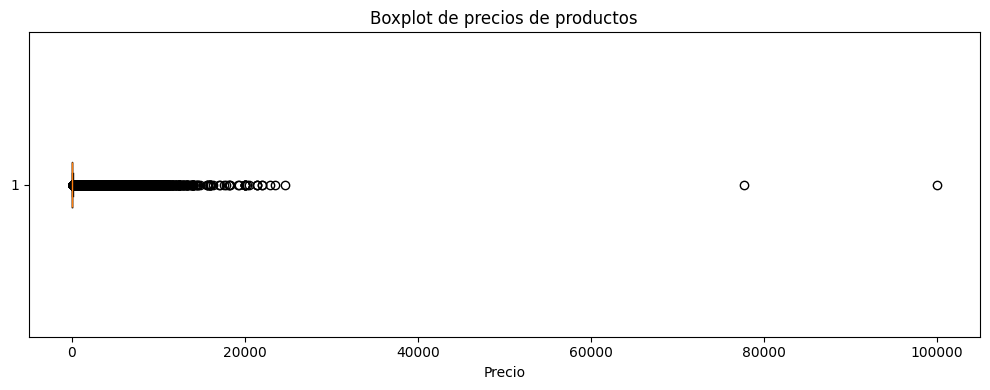

In [ ]:
# boxplot de precios
plt.figure(figsize=(10, 4))
plt.boxplot(price_data, vert=False)
plt.title("Boxplot de precios de productos")
plt.xlabel("Precio")
plt.tight_layout()
plt.show()

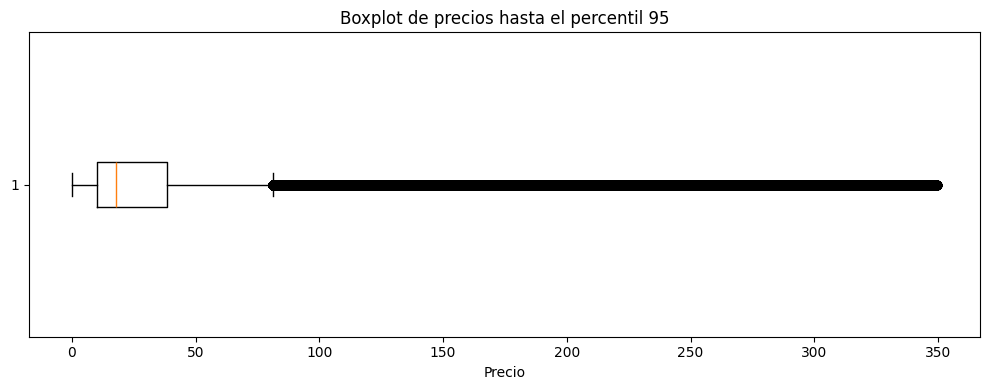

In [ ]:
# boxplot filtrado
plt.figure(figsize=(10, 4))
plt.boxplot(filtered_price_data, vert=False)
plt.title("Boxplot de precios hasta el percentil 95")
plt.xlabel("Precio")
plt.tight_layout()
plt.show()

### Conclusión de negocio - Precios

El análisis de precios permite entender cuál es el precio típico de los productos y si existen valores extremos.

Si la media es superior a la mediana, esto sugiere que algunos productos caros están elevando el promedio.

Desde una perspectiva de negocio, esto significa que:

- la media puede no representar correctamente el precio típico,
- la mediana puede ser más útil para entender el mercado general,
- los outliers pueden representar productos premium o errores de datos,
- la estrategia de precios debería analizarse también por categoría.

## Parte 3: Análisis de valoraciones de productos

### Pregunta de negocio

¿Cómo valoran los clientes los productos de Amazon UK?

En esta sección analizaremos los ratings para entender si los productos suelen tener buenas valoraciones, si las valoraciones son consistentes y si la distribución se inclina hacia valores altos o bajos.

In [ ]:
# definir columna de rating
rating_col = "stars"

df[rating_col].head()

0    4.7
1    4.7
2    4.7
3    4.7
4    4.6
Name: stars, dtype: float64

In [ ]:
# convertir ratings a números
df[rating_col] = pd.to_numeric(df[rating_col], errors="coerce")

rating_data = df[rating_col].dropna()

rating_data.describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

## Medidas de centralidad del rating

In [ ]:
rating_mean = rating_data.mean()
rating_median = rating_data.median()
rating_mode = rating_data.mode()[0]

print(f"Rating medio: {rating_mean:.2f}")
print(f"Rating mediano: {rating_median:.2f}")
print(f"Rating más frecuente: {rating_mode:.2f}")

Rating medio: 2.15
Rating mediano: 0.00
Rating más frecuente: 0.00


### Interpretación - Medidas de centralidad del rating

La media muestra la valoración promedio de los productos.

La mediana muestra la valoración central.

La moda muestra la valoración que más se repite.

Si la media, la mediana y la moda son altas, esto indica que los productos suelen estar bien valorados por los clientes.

## Medidas de dispersión del rating

In [ ]:
rating_variance = rating_data.var()
rating_std = rating_data.std()
rating_iqr = rating_data.quantile(0.75) - rating_data.quantile(0.25)

print(f"Varianza: {rating_variance:.2f}")
print(f"Desviación estándar: {rating_std:.2f}")
print(f"Rango intercuartílico IQR: {rating_iqr:.2f}")

Varianza: 4.82
Desviación estándar: 2.19
Rango intercuartílico IQR: 4.40


### Interpretación - Dispersión del rating

La varianza y la desviación estándar permiten saber si las valoraciones son consistentes o muy variables.

Una desviación estándar baja indica que la mayoría de productos tienen valoraciones parecidas.

Una desviación estándar alta indica que existe mayor diferencia en la percepción de los clientes.

## Forma de la distribución

In [ ]:
# skewness y kurtosis
rating_skewness = rating_data.skew()
rating_kurtosis = rating_data.kurtosis()

print(f"Asimetría: {rating_skewness:.2f}")
print(f"Curtosis: {rating_kurtosis:.2f}")

Asimetría: 0.08
Curtosis: -1.93


### Interpretación - Forma de la distribución del rating

La asimetría indica si la distribución se inclina hacia valores altos o bajos.

- Si la asimetría es negativa, los ratings tienden a concentrarse en valores altos.
- Si la asimetría es positiva, los ratings tienden a concentrarse en valores bajos.

La curtosis indica si la distribución tiene valores extremos o una concentración fuerte alrededor de ciertos valores.

Una curtosis alta puede indicar una distribución con valores muy concentrados o con colas más extremas.

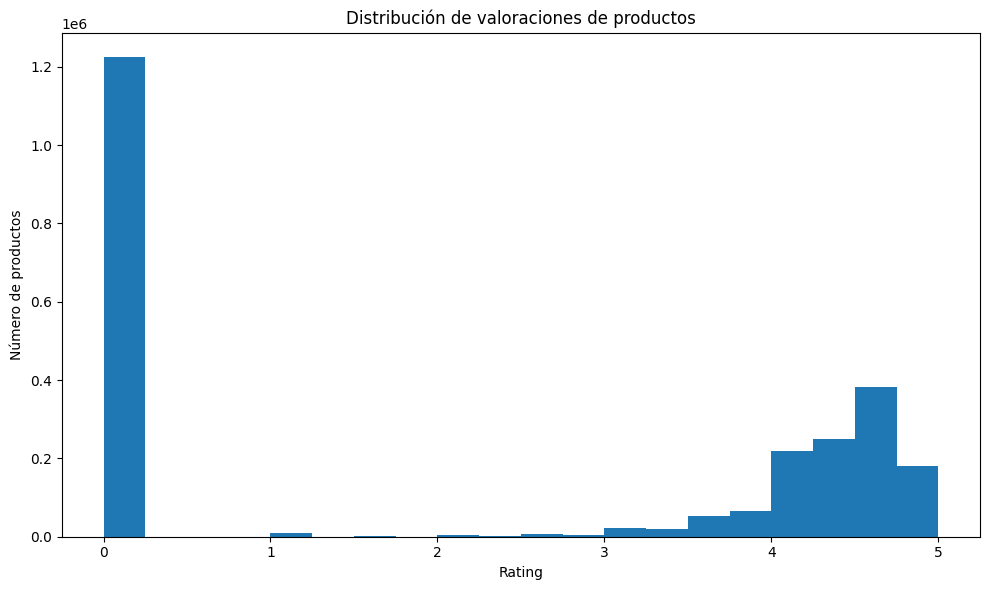

In [ ]:
# histograma de ratings
plt.figure(figsize=(10, 6))
plt.hist(rating_data, bins=20)
plt.title("Distribución de valoraciones de productos")
plt.xlabel("Rating")
plt.ylabel("Número de productos")
plt.tight_layout()
plt.show()

### Conclusión de negocio - Ratings

El análisis de ratings permite entender cómo perciben los clientes los productos publicados en Amazon UK.

Si los ratings se concentran en valores altos, esto indica una percepción general positiva.

Sin embargo, si muchos productos tienen valoraciones similares, el rating por sí solo puede no ser suficiente para diferenciar productos.

Desde una perspectiva de negocio, conviene combinar el rating con otras variables como:

- número de reviews,
- precio,
- categoría,
- marca,
- nivel de competencia.

## Conclusión final de negocio

El análisis exploratorio univariado del dataset de Amazon UK permite obtener una primera visión sobre la estructura del catálogo, los precios y las valoraciones de los productos.

En primer lugar, la distribución de categorías muestra que algunos tipos de productos tienen una presencia mucho mayor que otros. Esto puede indicar categorías con alta actividad comercial, pero también con mayor competencia entre vendedores.

En segundo lugar, el análisis de precios muestra si los productos se concentran en rangos bajos, medios o altos. Si existen valores extremos, la media puede verse distorsionada, por lo que la mediana puede representar mejor el precio típico del mercado.

En tercer lugar, el análisis de ratings permite entender cómo valoran los clientes los productos. Si las valoraciones se concentran en valores altos, esto puede indicar una percepción positiva general. Sin embargo, si muchos productos tienen ratings similares, será necesario combinar esta variable con otras como precio, número de reviews, categoría y marca.

En conclusión, este análisis sirve como primera base para tomar decisiones sobre posicionamiento, estrategia de precios, gestión de catálogo y análisis de competencia dentro de Amazon UK.